# CNN for Cat and Dog Classification (Keras)
Prepare train/validation/test data, train a CNN for 10 epochs, evaluate it, and visualize predictions.

In [1]:
import os
import shutil
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import image_dataset_from_directory

random.seed(42)
tf.random.set_seed(42)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

2026-11-17 19:09:55.813495: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Unzip the dataset

In [2]:
zip_path = "data_from_kaggle.zip"
source_path = "data_from_kaggle"
output_path = "dataset"

if not os.path.exists(source_path):  # unzip only once
    shutil.unpack_archive(zip_path)
print(os.listdir(source_path))

['test', 'train']


## 2. Prepare train / validation / test folders
`data_from_kaggle/train` is split 80/20 into train and validation. `data_from_kaggle/test` is the test set.

In [3]:
train_ratio = 0.8
train_source = os.path.join(source_path, "train")
test_source = os.path.join(source_path, "test")

def list_images(folder, cls):
    return sorted(f for f in os.listdir(folder) if f.lower().startswith(cls))

cat_imgs = list_images(train_source, "cat")
dog_imgs = list_images(train_source, "dog")
random.shuffle(cat_imgs)
random.shuffle(dog_imgs)

cat_split = int(len(cat_imgs) * train_ratio)
dog_split = int(len(dog_imgs) * train_ratio)

splits = {
    ("train", "cat"): (train_source, cat_imgs[:cat_split]),
    ("train", "dog"): (train_source, dog_imgs[:dog_split]),
    ("validation", "cat"): (train_source, cat_imgs[cat_split:]),
    ("validation", "dog"): (train_source, dog_imgs[dog_split:]),
    ("test", "cat"): (test_source, list_images(test_source, "cat")),
    ("test", "dog"): (test_source, list_images(test_source, "dog")),
}

In [4]:
if os.path.exists(output_path):  # rebuild cleanly on every run
    shutil.rmtree(output_path)

for (split, cls), (src, files) in splits.items():
    dst = os.path.join(output_path, split, cls)
    os.makedirs(dst, exist_ok=True)
    for f in files:
        shutil.copy(os.path.join(src, f), os.path.join(dst, f))

for split in ["train", "validation", "test"]:
    n_cat = len(os.listdir(os.path.join(output_path, split, "cat")))
    n_dog = len(os.listdir(os.path.join(output_path, split, "dog")))
    print(f"{split:10s} cat: {n_cat:5d}  dog: {n_dog:5d}  total: {n_cat + n_dog}")

train      cat:  8000  dog:  7991  total: 15991
validation cat:  2000  dog:  1998  total: 3998
test       cat:  2500  dog:  2500  total: 5000


## 3. Load the datasets

In [5]:
IMG_SIZE = (200, 180)
BATCH_SIZE = 32
EPOCHS = 10

train_dataset = image_dataset_from_directory(os.path.join(output_path, "train"), image_size=IMG_SIZE,
                                             batch_size=BATCH_SIZE, label_mode="binary", shuffle=True, seed=42)
val_dataset = image_dataset_from_directory(os.path.join(output_path, "validation"), image_size=IMG_SIZE,
                                           batch_size=BATCH_SIZE, label_mode="binary", shuffle=False)
test_dataset = image_dataset_from_directory(os.path.join(output_path, "test"), image_size=IMG_SIZE,
                                            batch_size=BATCH_SIZE, label_mode="binary", shuffle=False)

class_names = train_dataset.class_names
print("Classes:", class_names)  # cat = 0, dog = 1

# prefetch so the GPU is not waiting on disk
AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.prefetch(AUTOTUNE)
val_dataset = val_dataset.prefetch(AUTOTUNE)
test_dataset = test_dataset.prefetch(AUTOTUNE)

Found 15991 files belonging to 2 classes.


I0000 00:00:1794960734.476249 1574804 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14782 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:d8:00.0, compute capability: 7.0


Found 3998 files belonging to 2 classes.
Found 5000 files belonging to 2 classes.
Classes: ['cat', 'dog']


2026-11-17 19:12:16.246114: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


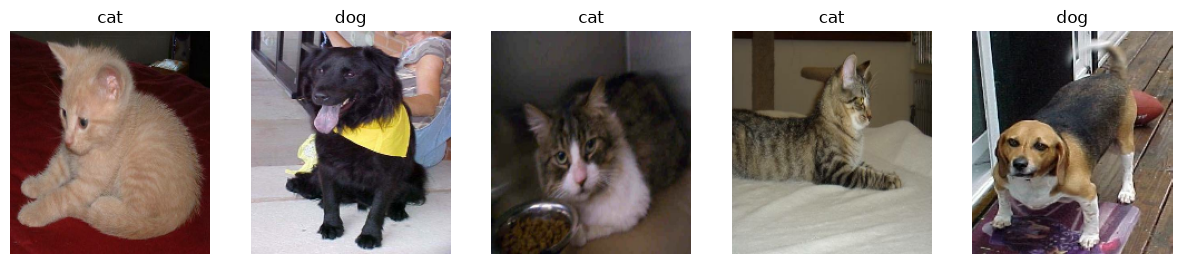

In [6]:
plt.figure(figsize=(15, 3))
for images, labels in train_dataset.take(1):
    for i in range(5):
        plt.subplot(1, 5, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i][0])])
        plt.axis("off")
plt.show()

## 4. Build the CNN

In [7]:
def build_model():
    inputs = keras.Input(shape=IMG_SIZE + (3,))
    x = layers.Rescaling(1.0 / 255)(inputs)  # pixels to [0, 1]
    x = layers.Conv2D(32, 3, activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(64, 3, activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(128, 3, activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(256, 3, activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(256, 3, activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Flatten()(x)
    x = layers.Dropout(0.5)(x)  # reduce overfitting
    outputs = layers.Dense(1, activation="sigmoid")(x)  # probability of dog
    return keras.Model(inputs, outputs)

model = build_model()
model.compile(optimizer="rmsprop", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 200, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 200, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 198, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 99, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 97, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 48, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 46, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 23, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 21, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 10, 9, 256)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 7, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 4, 3, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         3,073 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 981,569 (3.74 MB)

 Trainable params: 981,569 (3.74 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Train (epochs = 10)

In [8]:
history = model.fit(train_dataset, epochs=EPOCHS, validation_data=val_dataset, verbose=2)

Epoch 1/10


/home/ksathwik/.conda/envs/ece-5831-2026/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
2026-11-17 19:12:18.425448: I external/local_xla/xla/service/service.cc:163] XLA service 0x149a8c009c80 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-11-17 19:12:18.425470: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): Tesla V100-PCIE-16GB, Compute Capability 7.0
2026-11-17 19:12:18.457159: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-11-17 19:12:18.734433: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 903

500/500 - 17s - 34ms/step - accuracy: 0.6217 - loss: 0.6429 - val_accuracy: 0.7469 - val_loss: 0.5279
Epoch 2/10
500/500 - 9s - 17ms/step - accuracy: 0.7357 - loss: 0.5314 - val_accuracy: 0.7636 - val_loss: 0.5056
Epoch 3/10
500/500 - 8s - 17ms/step - accuracy: 0.7946 - loss: 0.4427 - val_accuracy: 0.8274 - val_loss: 0.3984
Epoch 4/10
500/500 - 8s - 17ms/step - accuracy: 0.8345 - loss: 0.3682 - val_accuracy: 0.8549 - val_loss: 0.3494
Epoch 5/10
500/500 - 9s - 17ms/step - accuracy: 0.8682 - loss: 0.3046 - val_accuracy: 0.8842 - val_loss: 0.2862
Epoch 6/10
500/500 - 9s - 17ms/step - accuracy: 0.8904 - loss: 0.2601 - val_accuracy: 0.8879 - val_loss: 0.2971
Epoch 7/10
500/500 - 9s - 17ms/step - accuracy: 0.9091 - loss: 0.2220 - val_accuracy: 0.8639 - val_loss: 0.3920
Epoch 8/10
500/500 - 9s - 17ms/step - accuracy: 0.9206 - loss: 0.1917 - val_accuracy: 0.9065 - val_loss: 0.2621
Epoch 9/10
500/500 - 9s - 17ms/step - accuracy: 0.9335 - loss: 0.1666 - val_accuracy: 0.9090 - val_loss: 0.3041
Ep

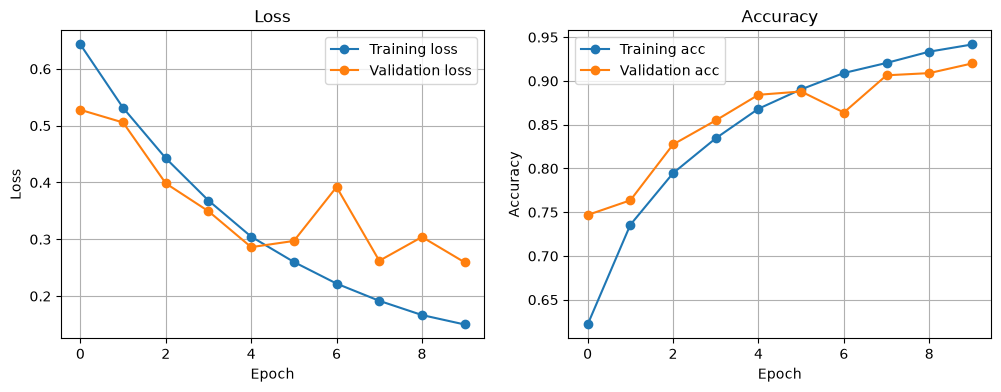

In [9]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], marker="o", label="Training loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Loss"); plt.legend(); plt.grid()
plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], marker="o", label="Training acc")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation acc")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("Accuracy"); plt.legend(); plt.grid()
plt.show()

## 6. Evaluate on validation and test sets

In [10]:
val_loss, val_acc = model.evaluate(val_dataset, verbose=0)
test_loss, test_acc = model.evaluate(test_dataset, verbose=0)
print(f"Validation loss: {val_loss:.4f}  accuracy: {val_acc:.4f}")
print(f"Test loss:       {test_loss:.4f}  accuracy: {test_acc:.4f}")

2026-11-17 19:13:54.607103: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:546] Omitted potentially buggy algorithm eng14{k25=0} for conv (f32[8,32,198,178]{3,2,1,0}, u8[0]{0}) custom-call(f32[8,3,200,180]{3,2,1,0}, f32[32,3,3,3]{3,2,1,0}, f32[32]{0}), window={size=3x3}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kRelu","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false,"reification_cost":[]}
2026-11-17 19:13:54.644971: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:546] Omitted potentially buggy algorithm eng14{k25=0} for conv (f32[8,64,97,87]{3,2,1,0}, u8[0]{0}) custom-call(f32[8,32,99,89]{3,2,1,0}, f32[64,32,3,3]{3,2,1,0}, f32[64]{0}), window={size=3x3}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationFor

Validation loss: 0.2594  accuracy: 0.9200
Test loss:       0.2717  accuracy: 0.9150


In [11]:
# confusion matrix on the test set
y_true = np.concatenate([y.numpy().flatten() for _, y in test_dataset]).astype(int)
y_prob = model.predict(test_dataset, verbose=0).flatten()
y_pred = (y_prob > 0.5).astype(int)

cm = tf.math.confusion_matrix(y_true, y_pred).numpy()
print("Rows = true, columns = predicted", class_names)
print(cm)
print(f"Test accuracy (manual): {np.mean(y_pred == y_true):.4f}")

2026-11-17 19:13:56.735585: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Rows = true, columns = predicted ['cat', 'dog']
[[2264  236]
 [ 189 2311]]
Test accuracy (manual): 0.9150


## 7. Prediction examples (predicted vs. true)

Found 5000 files belonging to 2 classes.


2026-11-17 19:14:00.135169: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:546] Omitted potentially buggy algorithm eng14{k25=0} for conv (f32[12,32,198,178]{3,2,1,0}, u8[0]{0}) custom-call(f32[12,3,200,180]{3,2,1,0}, f32[32,3,3,3]{3,2,1,0}, f32[32]{0}), window={size=3x3}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kRelu","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false,"reification_cost":[]}
2026-11-17 19:14:00.183540: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:546] Omitted potentially buggy algorithm eng14{k25=0} for conv (f32[12,64,97,87]{3,2,1,0}, u8[0]{0}) custom-call(f32[12,32,99,89]{3,2,1,0}, f32[64,32,3,3]{3,2,1,0}, f32[64]{0}), window={size=3x3}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivatio

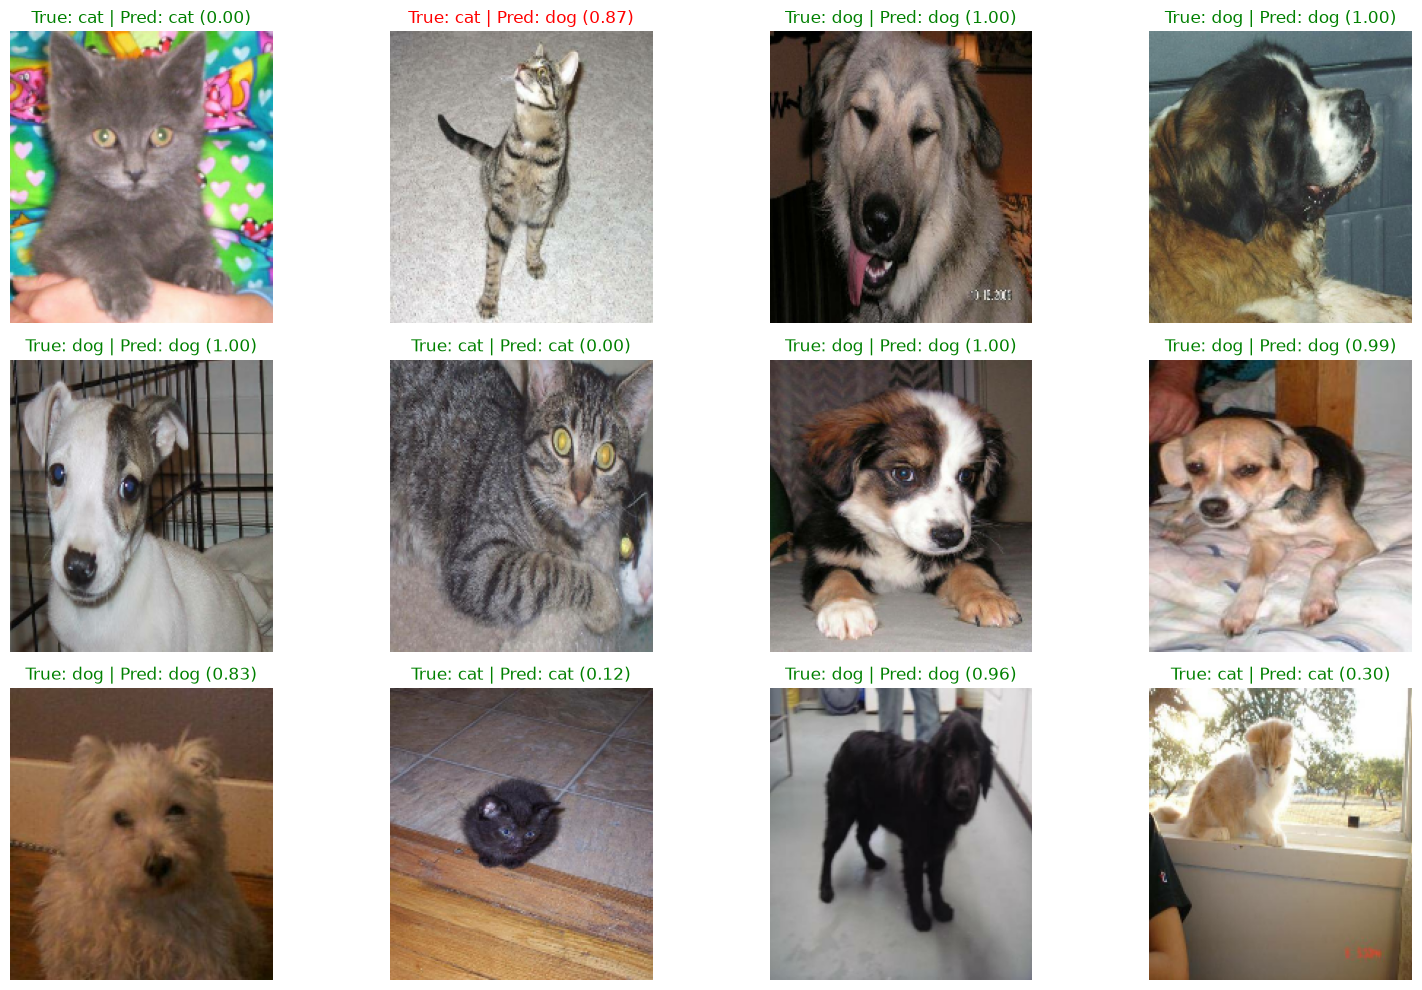

In [12]:
# take a shuffled batch so both cats and dogs appear
sample_ds = image_dataset_from_directory(os.path.join(output_path, "test"), image_size=IMG_SIZE,
                                         batch_size=12, label_mode="binary", shuffle=True, seed=7)
images, labels = next(iter(sample_ds))
probs = model.predict(images, verbose=0).flatten()

plt.figure(figsize=(16, 10))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    true_c = class_names[int(labels[i][0])]
    pred_c = class_names[int(probs[i] > 0.5)]
    color = "green" if true_c == pred_c else "red"
    plt.title(f"True: {true_c} | Pred: {pred_c} ({probs[i]:.2f})", color=color)
    plt.axis("off")
plt.tight_layout()
plt.show()

In [13]:
model.save("cnn_cat_dog.keras")
print("Model saved to cnn_cat_dog.keras")

Model saved to cnn_cat_dog.keras


## 8. Conclusion
- Training loss falls and accuracy rises over 10 epochs, so training works.
- Validation and test accuracy above are measured on images the model never trained on, so evaluation works.
- Green titles are correct predictions, red titles are mistakes.